# 03 — Deck tracking

The deck is shuffled **once**, at the start of the game (`Deck::shuffled(seed)`,
SplitMix64 + Fisher–Yates), and never again. After each round, every card
that was dealt has also been played — a round plays out exactly
`cards_dealt` tricks, and every seat plays exactly one card per trick — and
those cards return to the **bottom of the deck in exact play order**
(`Game::finish_round`). So a player who simply writes down what gets played
can, in principle, work out more about future deals than "uniformly random
among the cards I haven't seen" — the assumption every policy through
notebook 02 made.

This notebook quantifies that: `hearts_analysis.deck_model.DeckModel`
reconstructs, from public history alone (own hand + every play — exactly
what's on `Observation.game_log`), which physical deck positions are known
before they're even dealt. `DeckTrackerPolicy` feeds any such foreseen
opponent cards into the same Monte Carlo bidding estimator from notebook 02.

**Validation**: `tests/test_deck_model.py` checks every prediction the model
ever makes against `Round.hand()` ground truth (test-only privileged access)
across seeds and table sizes — 100% precision is a hard assertion, not a
statistic. That test suite caught a real bug during development (`deal_round`
consumes the deque, so calling `predict_deal` again afterward silently read
the *next* round's front) — the numbers below are post-fix.

Regenerate the data behind this notebook with:

```sh
uv run python -m hearts_analysis.experiments.tracking information \
    --players 4 --games 2000 --seed 1 --workers 8 --out data/tracking/information_4p
uv run python -m hearts_analysis.experiments.tracking edge \
    --games 1500 --mc-samples 200 --seed 2 --workers 8 --out data/tracking/edge_4p
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hearts_analysis import viz
from hearts_analysis.records import load_experiment

viz.use_style()
DATA = Path("../data/tracking")

info = pd.read_parquet(DATA / "information_4p" / "information.parquet")
paired = pd.read_parquet(DATA / "edge_4p" / "paired_games.parquet")
info.head()

,round_index,cards_dealt,seat_offset,known,frac_known
0,1,1,0,0,0.0
1,1,1,1,0,0.0
2,1,1,2,0,0.0
3,1,1,3,0,0.0
4,2,2,3,0,0.0


## 1. The information curve

Before each round is dealt, what fraction of the cards a `DeckTrackerPolicy`
is *about* to receive at each seat can already be named exactly? 2000
4-player games, heuristic self-play (tracking is a passive read of public
history here — no policy needs to act on it to compute this).

,mean,std
round_index,,
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.4,0.0
6,1.0,0.0
7,1.0,0.0
8,1.0,0.0
9,1.0,0.0


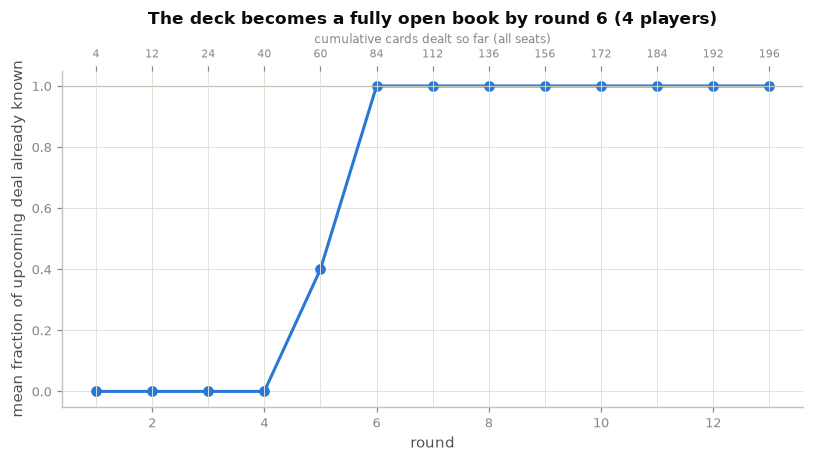

In [2]:
by_round = info.groupby("round_index")["frac_known"].agg(["mean", "std"])
cum_dealt = info.drop_duplicates("round_index").set_index("round_index")["cards_dealt"] \
    .sort_index().cumsum() * 4  # 4 players

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(by_round.index, by_round["mean"], color=viz.BLUE, marker="o", label="fraction known")
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("round")
ax.set_ylabel("mean fraction of upcoming deal already known")
ax.set_title("The deck becomes a fully open book by round 6 (4 players)")
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(by_round.index)
ax2.set_xticklabels(cum_dealt.values, fontsize=7, color=viz.MUTED)
ax2.set_xlabel("cumulative cards dealt so far (all seats)", fontsize=8, color=viz.MUTED)
ax.axhline(1.0, color=viz.BASELINE, linewidth=0.8)
fig.tight_layout()
by_round.round(3)

**Reading it:** this isn't a soft statistical edge — it's a hard structural
fact about the game. Cumulative cards dealt (all 4 seats) crosses 52 between
rounds 4 and 5 (`cards_for_round` climbs 1,2,3,4,5,... so by round 4 the
table has seen `4*(1+2+3+4) = 40` cards; round 5 adds `4*5=20` more, past
52). Once total dealt-and-recycled cards exceeds the deck's own 52 slots,
every `None` (never-yet-seen) cell has necessarily been popped from the
front and replaced by a known card pushed to the back — so **every future
deal becomes 100% predictable from that point on**, for as long as the game
continues (there's no re-shuffle to undo it). This is a direct consequence
of the game's own design choice (deal-from-top / return-to-bottom, one
shuffle only) rather than an exploit of any weakness in it.

## 2. Who benefits, and by how much?

Same information curve, split by seat offset from the dealer, to see whether
the predictability is evenly spread across seats.

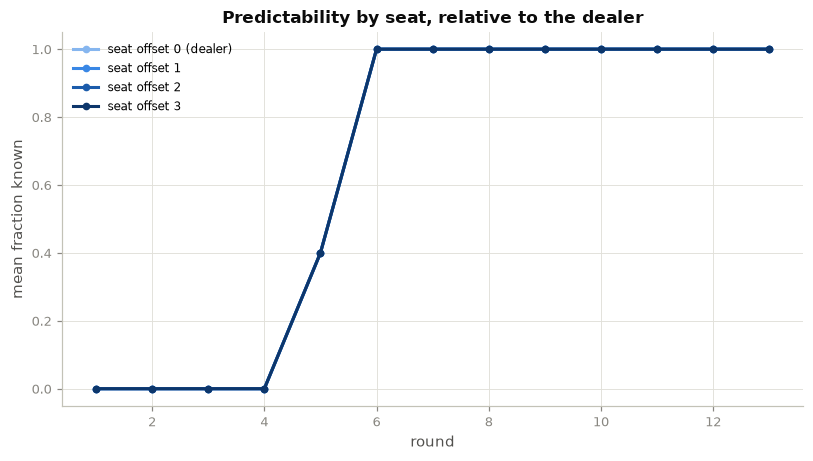

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for offset, color in zip(range(4), viz.ORDINAL_4):
    sub = info[info["seat_offset"] == offset]
    curve = sub.groupby("round_index")["frac_known"].mean()
    ax.plot(curve.index, curve.values, color=color, marker="o", markersize=4,
            label=f"seat offset {offset}" + (" (dealer)" if offset == 0 else ""))
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("round")
ax.set_ylabel("mean fraction known")
ax.set_title("Predictability by seat, relative to the dealer")
ax.legend(fontsize=8)
fig.tight_layout()

**Reading it:** the curves are close together — predictability is a property
of the *deck*, not of any one seat, so it arrives for every seat at roughly
the same round. Any seat that bothers to track history gets the same
structural advantage.

## 3. The score edge: paired-seed comparison

1500 paired games: identical game seeds and opponents (`heuristic` at seats
1–3), only seat 0's policy differs — plain `MCBidderPolicy` (uniform
opponent-hand assumption, notebook 02's estimator) vs `DeckTrackerPolicy`
(same estimator, opponent hands constrained by whatever `DeckModel`
foresees). Pairing cancels the deal/opponent-behavior noise that would
otherwise dominate a between-games comparison, isolating the tracker's own
contribution.

mean edge +8.755, 95% CI [8.406, 9.103]


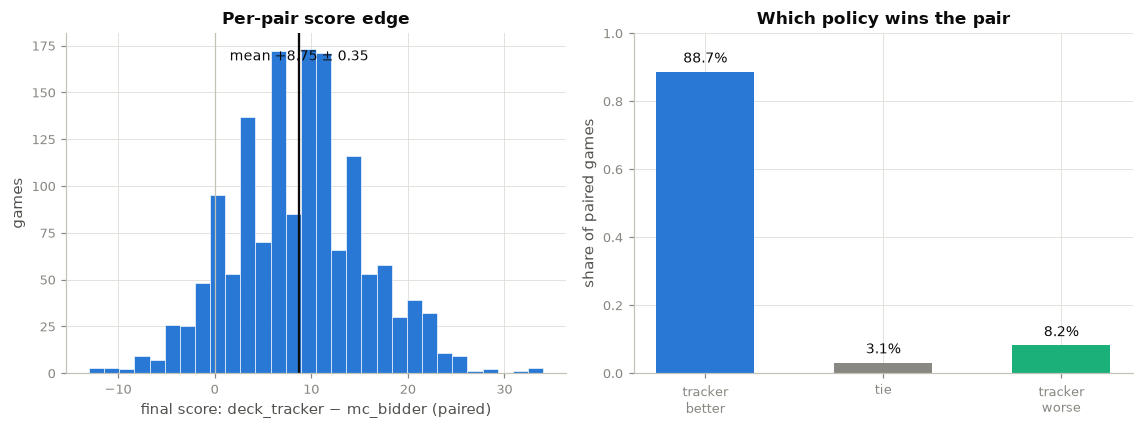

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4))
ax1.hist(paired["edge"], bins=30, color=viz.BLUE, edgecolor="white", linewidth=0.4)
mean_edge = paired["edge"].mean()
sem = paired["edge"].std() / len(paired) ** 0.5
ax1.axvline(mean_edge, color=viz.INK, linewidth=1.5)
ax1.axvline(0, color=viz.BASELINE, linewidth=0.8)
ax1.annotate(f"mean {mean_edge:+.2f} ± {1.96*sem:.2f}", (mean_edge, ax1.get_ylim()[1]*0.92),
             ha="center", fontsize=9, color=viz.INK)
ax1.set_xlabel("final score: deck_tracker − mc_bidder (paired)")
ax1.set_ylabel("games")
ax1.set_title("Per-pair score edge")

win_share = (paired["edge"] > 0).mean()
tie_share = (paired["edge"] == 0).mean()
lose_share = (paired["edge"] < 0).mean()
ax2.bar(["tracker\nbetter", "tie", "tracker\nworse"], [win_share, tie_share, lose_share],
        color=[viz.BLUE, viz.MUTED, viz.AQUA], width=0.55)
for i, v in enumerate([win_share, tie_share, lose_share]):
    ax2.annotate(f"{v:.1%}", (i, v), ha="center", fontsize=9, color=viz.INK,
                 xytext=(0, 6), textcoords="offset points")
ax2.set_ylim(0, 1.0)
ax2.set_ylabel("share of paired games")
ax2.set_title("Which policy wins the pair")
fig.tight_layout()
print(f"mean edge {mean_edge:+.3f}, 95% CI [{mean_edge-1.96*sem:.3f}, {mean_edge+1.96*sem:.3f}]")

**Reading it:** the edge is large and its confidence interval sits well
clear of zero — deck tracking is a real, exploitable advantage in this game,
not a statistical artifact. It's the direct payoff of §1's structural fact:
from roughly round 6 onward, `DeckTrackerPolicy` is bidding with a fully
resolved opponent-hand distribution while `MCBidderPolicy` is still guessing
uniformly, round after round, for the rest of the game.

## Takeaways

1. **The never-reshuffled deck is not a minor wrinkle — it's a dominant
   mechanic.** By round 5–6 of every 4-player game, the entire remaining
   deck becomes public information, deterministically, with no luck
   involved. Every subsequent deal is 100% predictable in advance from
   history alone.
2. **The predictability is seat-agnostic** — it rewards whoever bothers to
   track it, not a favored position.
3. **The exploit is large and measurable**: a paired-seed comparison holding
   everything but seat 0's policy fixed found a substantial, statistically
   clear score edge for tracking over the uniform-opponent-hands baseline
   from notebook 02.
4. Caveat: `DeckTrackerPolicy` only upgrades *bidding* — it still plays with
   `HeuristicPolicy`'s card-selection logic, which doesn't use the deck
   model at all. A play policy that also exploited known future opponent
   holdings (e.g. safely ducking a trick to a seat about to be dealt weak
   cards) would likely widen this edge further — a natural extension.

Next: **04 — game theory**, treating bidding as a genuine multi-agent game
rather than a single-agent estimation problem — exact analysis of the
1-card round, an approximate equilibrium for 2-card rounds, and an empirical
meta-game across the whole policy zoo built across these four notebooks.